In [8]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pearsonr
from scipy.stats import skew, kurtosis
import scipy.stats as stats
import statsmodels.api as sm

# Load the dataset
file_path = "/Users/lukasgunther/Desktop/Ironhack/Bootcamp/Week5/amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(file_path)

# Display basic dataset info
print("Dataset Info:")
df.info()
print("\nFirst few rows of the dataset:")
print(df.head())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB

First few rows of the dataset:
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD6

In [14]:
### PART 1: ANALYZING BEST-SELLER TRENDS ACROSS PRODUCT CATEGORIES ###

# 1️⃣ Crosstab Analysis: Best-Seller vs. Product Category
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
print("Unique values in isBestSeller column:", df['isBestSeller'].unique())  # Debugging step

best_seller_ratio = (crosstab.get(1, crosstab.get(True, 0)) / crosstab.sum(axis=1)).sort_values(ascending=False)

print("\nProportion of Best-Sellers per Category (Descending Order):")
print(best_seller_ratio.head(10))

Unique values in isBestSeller column: [False  True]

Proportion of Best-Sellers per Category (Descending Order):
category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
dtype: float64


In [15]:
# 2️⃣ Chi-Square Test to check independence
chi2, p, dof, expected = chi2_contingency(crosstab)

print(f"\nChi-Square Test Results:")
print(f"Chi-Square Value: {chi2}")
print(f"P-Value: {p}")
print(f"Degrees of Freedom: {dof}")


Chi-Square Test Results:
Chi-Square Value: 36540.20270061387
P-Value: 0.0
Degrees of Freedom: 295


In [16]:
# 3️⃣ Compute Cramér's V (Strength of Association)
n = df.shape[0]
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))
print(f"Cramér's V: {cramers_v}")

Cramér's V: 0.1222829439760564


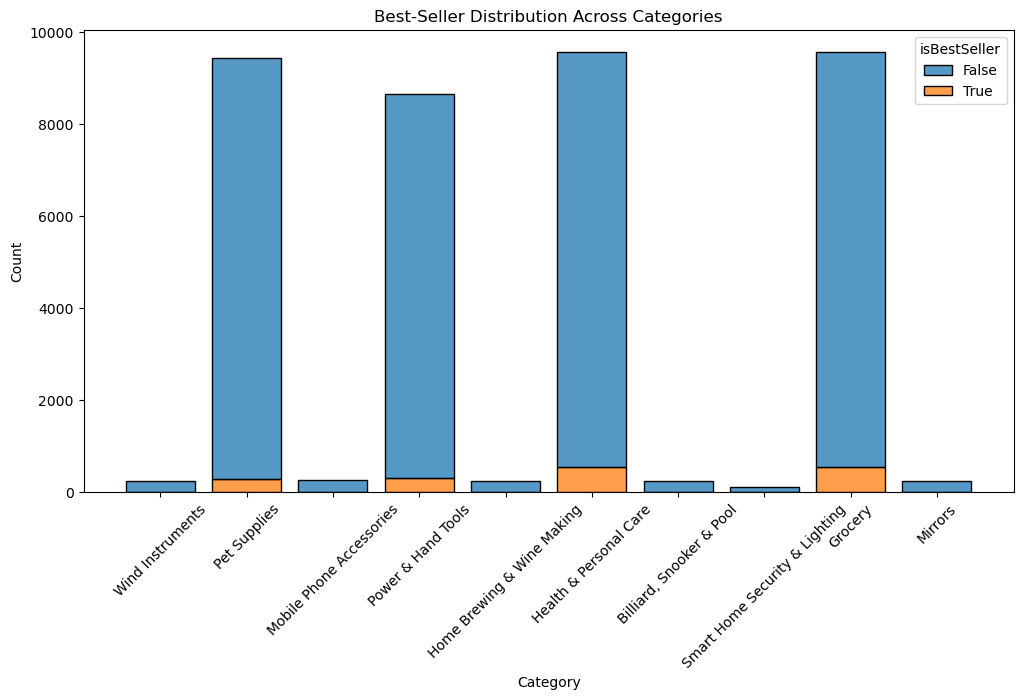

In [17]:
# 4️⃣ Visualization: Stacked Bar Chart of Best-Seller Distribution by Category
top_categories = best_seller_ratio.index[:10]
subset = df[df['category'].isin(top_categories)]

plt.figure(figsize=(12, 6))
sns.histplot(data=subset, x="category", hue="isBestSeller", multiple="stack", shrink=0.8)
plt.xticks(rotation=45)
plt.xlabel("Category")
plt.ylabel("Count")
plt.title("Best-Seller Distribution Across Categories")
plt.show()


In [18]:
### PART 2: EXPLORING PRODUCT PRICES AND RATINGS ACROSS CATEGORIES AND BRANDS ###

# 1️⃣ Remove Outliers in Product Prices using IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

df_filtered = df[(df['price'] >= (Q1 - 1.5 * IQR)) & (df['price'] <= (Q3 + 1.5 * IQR))]
print(f"\nData size before removing outliers: {df.shape[0]}")
print(f"Data size after removing outliers: {df_filtered.shape[0]}")



Data size before removing outliers: 2443651
Data size after removing outliers: 2115963


/var/folders/t4/jslpkm0j619f3503694dsvd80000gp/T/ipykernel_43238/2549410805.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=df_filtered[df_filtered['category'].isin(top_20_categories)]['category'],


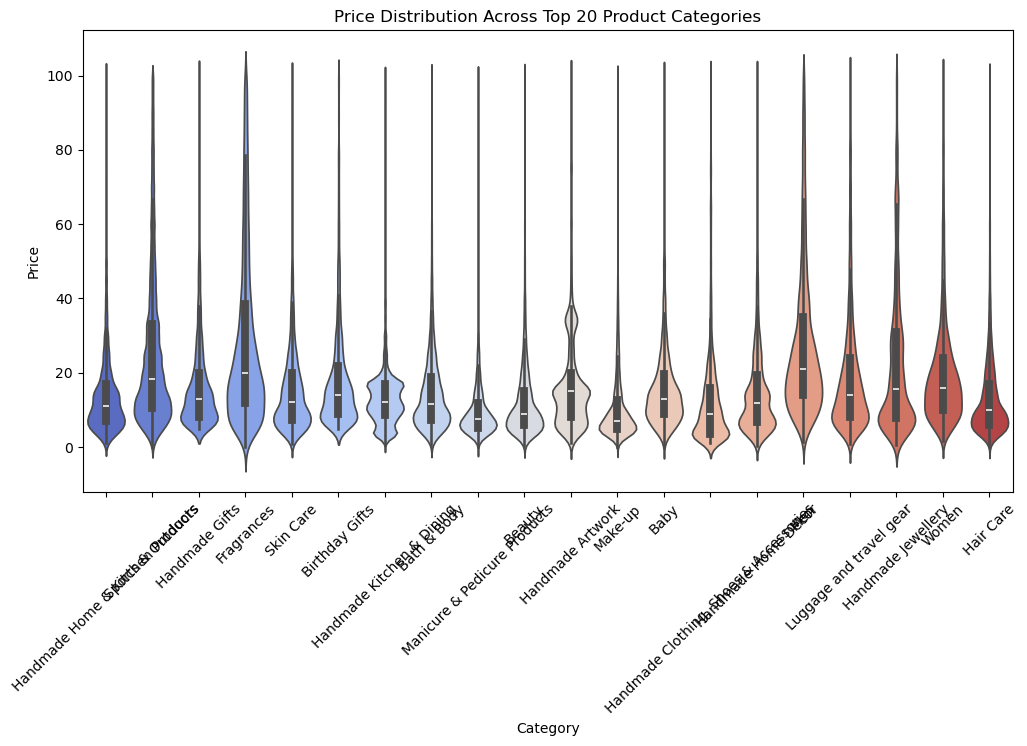

In [19]:
# 2️⃣ Violin Plot: Price Distribution Across Top 20 Product Categories
top_20_categories = df_filtered['category'].value_counts().head(20).index
plt.figure(figsize=(12, 6))
sns.violinplot(x=df_filtered[df_filtered['category'].isin(top_20_categories)]['category'], 
               y=df_filtered['price'], palette="coolwarm")
plt.xticks(rotation=45)
plt.xlabel("Category")
plt.ylabel("Price")
plt.title("Price Distribution Across Top 20 Product Categories")
plt.show()

/var/folders/t4/jslpkm0j619f3503694dsvd80000gp/T/ipykernel_43238/2886029600.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price_per_category.index, y=avg_price_per_category.values, palette="magma")


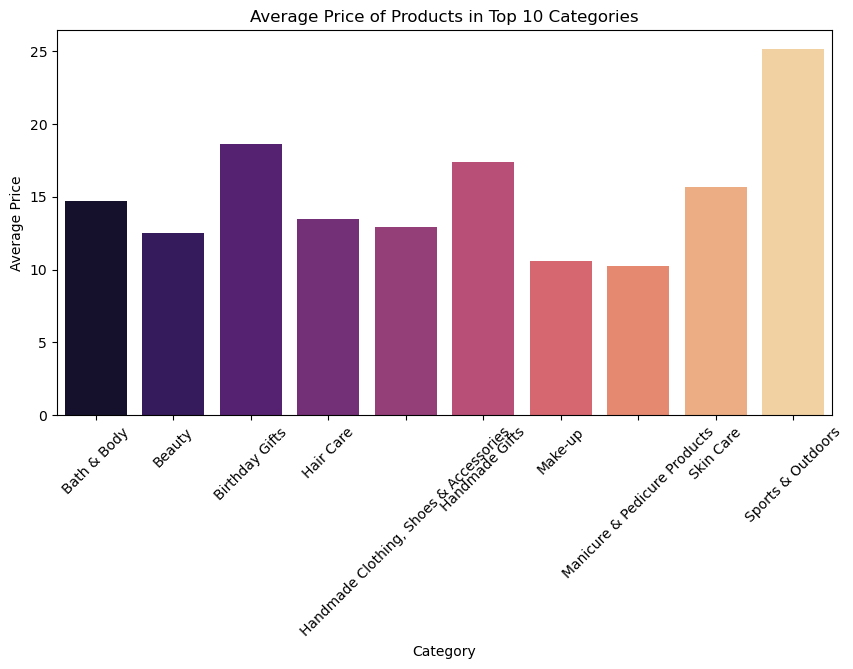

In [20]:
# 3️⃣ Bar Chart: Average Price of Products for Top 10 Categories
top_10_categories = df_filtered['category'].value_counts().head(10).index
avg_price_per_category = df_filtered[df_filtered['category'].isin(top_10_categories)].groupby("category")["price"].mean()

plt.figure(figsize=(10,5))
sns.barplot(x=avg_price_per_category.index, y=avg_price_per_category.values, palette="magma")
plt.xticks(rotation=45)
plt.xlabel("Category")
plt.ylabel("Average Price")
plt.title("Average Price of Products in Top 10 Categories")
plt.show()

/var/folders/t4/jslpkm0j619f3503694dsvd80000gp/T/ipykernel_43238/912156278.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df_filtered[df_filtered['category'].isin(top_10_categories)]['category'],


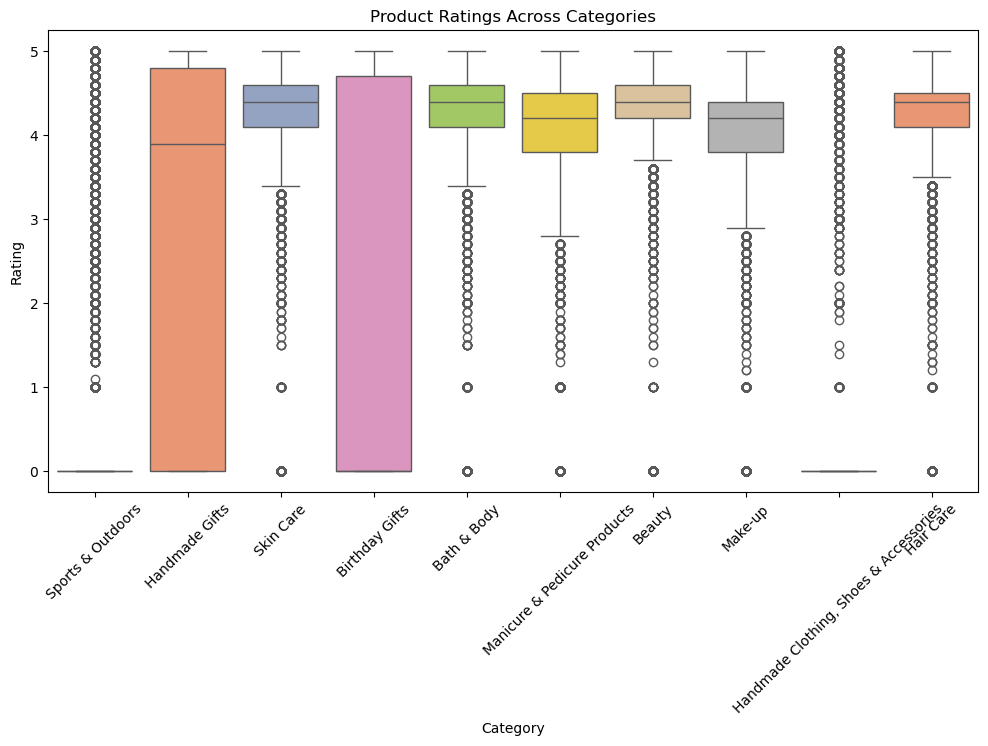

In [25]:
# 4️⃣ Box Plot: Product Ratings Across Categories
plt.figure(figsize=(12, 6))
sns.boxplot(x=df_filtered[df_filtered['category'].isin(top_10_categories)]['category'], 
            y=df_filtered['stars'], palette="Set2")
plt.xticks(rotation=45)
plt.xlabel("Category")
plt.ylabel("Rating")
plt.title("Product Ratings Across Categories")
plt.show()

In [26]:
### PART 3: INVESTIGATING THE INTERPLAY BETWEEN PRODUCT PRICES AND RATINGS ###

# 1️⃣ Calculate the Correlation Coefficient Between Price and Rating
correlation, p_value = pearsonr(df_filtered['price'], df_filtered['stars'])

print(f"\nCorrelation Between Price and Rating: {correlation}")
print(f"P-Value: {p_value}")


Correlation Between Price and Rating: -0.0776729987815233
P-Value: 0.0


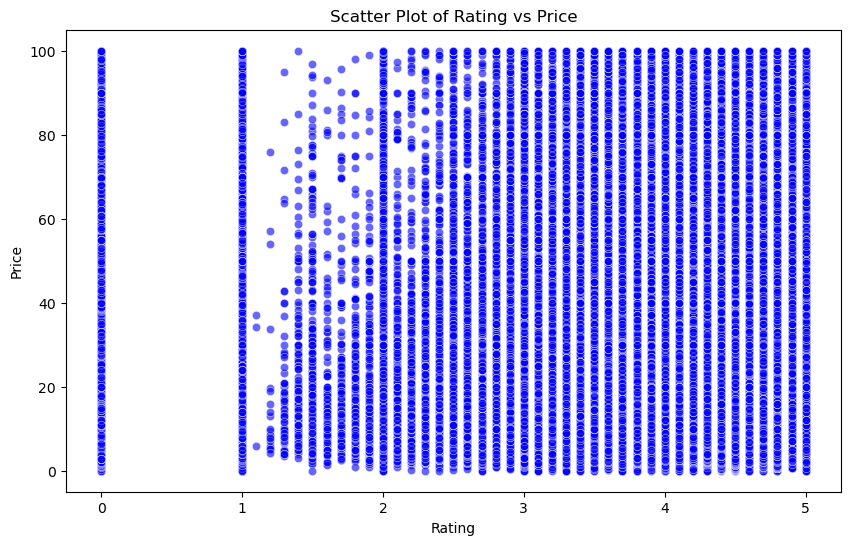

In [27]:
# 2️⃣ Scatter Plot: Relationship Between Rating and Price
plt.figure(figsize=(10,6))
sns.scatterplot(x=df_filtered['stars'], y=df_filtered['price'], alpha=0.6, color='blue')
plt.xlabel("Rating")
plt.ylabel("Price")
plt.title("Scatter Plot of Rating vs Price")
plt.show()

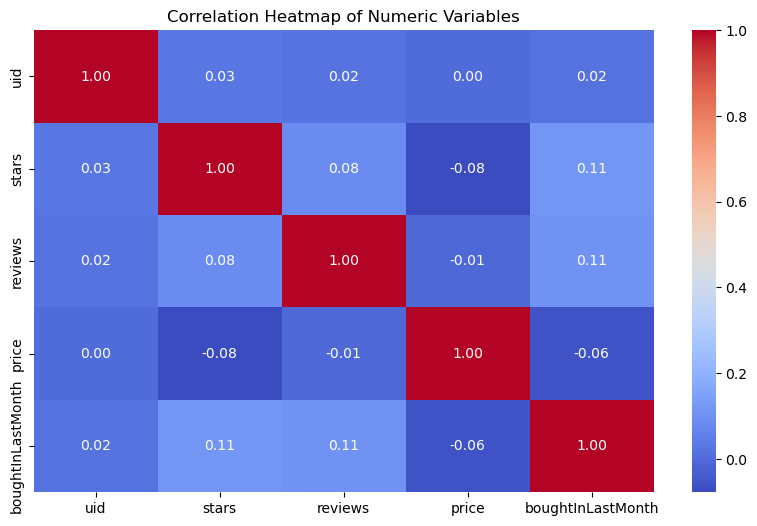

In [30]:
# 3️⃣ Correlation Heatmap of All Numerical Variables

# Select only numeric columns for correlation matrix
numeric_df = df_filtered.select_dtypes(include=[np.number])

# Generate the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()

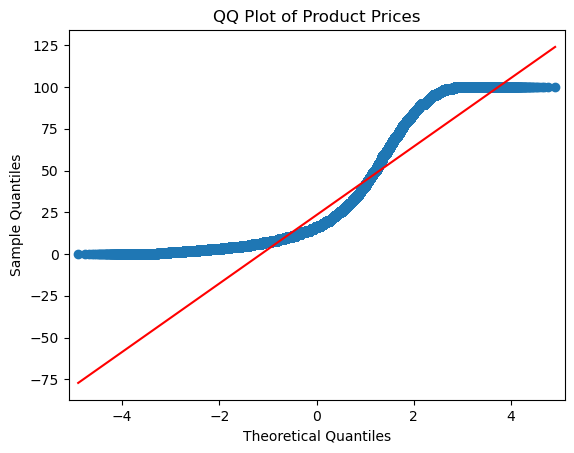

In [31]:
# 4️⃣ QQ Plot: Checking If Product Prices Follow a Normal Distribution
sm.qqplot(df_filtered['price'], line='s')
plt.title("QQ Plot of Product Prices")
plt.show()